# Riesgo y disrupción en cadenas de suministro globales — prototipo de portafolio

**Fecha de la revisión:** domingo 11 de octubre de 2026.

**Alcance.** Prototipo para portafolio que demuestra un flujo completo de análisis de datos (carga, limpieza, exploración, pruebas estadísticas, índice compuesto, matriz de riesgo y dashboard). No está validado para decisiones operativas.

**Fuente de datos.** Dataset publicado por *nudratabbas* en Kaggle, "Global Supply Chain Risk and Logistics 2024-2026" (archivo `global_supply_chain_risk_2026.csv`), licencia CC0. La ficha del dataset indica: *"Este conjunto de datos se generó sintéticamente y puede que no refleje datos del mundo real."*

**Período real de los datos:** del 1 de enero de 2024 al 31 de diciembre de 2025 (5.000 envíos). La ficha dice "2024-2026", pero el archivo no contiene datos de 2026.

## Alcance y limitaciones

- **Naturaleza sintética.** Los conteos son casi uniformes por categoría y la disrupción por huracán es 100%. Las conclusiones son ilustrativas, no diagnósticos de una red real.
- **Señal detectada.** El clima es la única variable con relación estadística fuerte con la disrupción (chi-cuadrado p < 0,0001).
- **Sin señal en rutas ni modos.** No se detectan diferencias mayores de unos 15 puntos porcentuales por ruta (≈70 envíos por ruta). Esto es compatible con datos sintéticos o con una ausencia de efecto en la muestra; el archivo no permite distinguirlas.
- **Criterios de la matriz.** Son provisionales y pendientes de validación. Solo 2 de 64 rutas superan de forma significativa la tasa global.
- **Decisiones.** Las acciones presentadas son hipótesis a validar con costo y evidencia; no son recomendaciones.

Ver la lista de decisiones metodológicas en el documento de revisión que acompaña a este notebook.


In [1]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ==================================================
# TEMA GLOBAL BASADO EN PALETA EQUINOR
# ==================================================

equinor_palette = {
    "energy_red": "#EB0037",
    "white": "#FFFFFF",
    "mist_blue": "#D5EAF4",
    "heritage_red": "#990024",
    "slate_grey": "#6F6F6F",
    "pickled_bluewood": "#253747"
}

# Paleta principal para gráficos
PALETA = [
    equinor_palette["energy_red"],
    equinor_palette["mist_blue"],
    equinor_palette["slate_grey"],
    equinor_palette["heritage_red"],
    equinor_palette["pickled_bluewood"]
]

# Tema seaborn global
sns.set_theme(
    style="whitegrid",
    context="talk",
    palette=PALETA
)

# Ajustes matplotlib globales
plt.rcParams["figure.figsize"] = (10,6)
plt.rcParams["figure.facecolor"] = equinor_palette["white"]
plt.rcParams["axes.facecolor"] = equinor_palette["white"]

plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlecolor"] = equinor_palette["pickled_bluewood"]

plt.rcParams["axes.labelsize"] = 12
plt.rcParams["axes.labelcolor"] = equinor_palette["pickled_bluewood"]

plt.rcParams["xtick.labelsize"] = 11
plt.rcParams["ytick.labelsize"] = 11
plt.rcParams["xtick.color"] = equinor_palette["slate_grey"]
plt.rcParams["ytick.color"] = equinor_palette["slate_grey"]

plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["grid.color"] = equinor_palette["slate_grey"]

plt.rcParams["legend.frameon"] = False
plt.rcParams["text.color"] = equinor_palette["pickled_bluewood"]

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.edgecolor"] = equinor_palette["slate_grey"]

# Heatmap Equinor
CMAP_HEATMAP = LinearSegmentedColormap.from_list(
    "equinor_heatmap",
    [
        equinor_palette["mist_blue"],
        equinor_palette["white"],
        equinor_palette["energy_red"],
        equinor_palette["heritage_red"]
    ]
)

## 1. Carga y Comprensión de Datos
Se carga el dataset `global_supply_chain_risk_2026.csv` (5.000 registros de envíos internacionales con variables operativas, climáticas y geopolíticas). Según el archivo, las fechas van de enero de 2024 a diciembre de 2025. El objetivo es comprender su estructura antes de cualquier transformación.


In [3]:
df=pd.read_csv("/mnt/user-data/uploads/global_supply_chain_risk_2026.csv")
df

,Shipment_ID,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred
0,SC-10000,2025-10-16,Singapore,Los Angeles,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1
1,SC-10001,2024-04-24,Singapore,Shanghai,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1
2,SC-10002,2024-01-26,Rotterdam,Los Angeles,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0
3,SC-10003,2024-10-08,Busan,Hamburg,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1
4,SC-10004,2024-09-07,Busan,Singapore,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,SC-14995,2025-11-10,Rotterdam,Dubai,Rail,Perishables,13512.26,428.97,3.35,8.8,Fog,0.664,20.28,0
4996,SC-14996,2025-11-23,Dubai,Shanghai,Air,Perishables,2231.02,448.86,1.79,0.5,Clear,0.863,0.50,0
4997,SC-14997,2025-10-18,Antwerp,Busan,Rail,Pharmaceuticals,5253.72,473.41,1.37,3.0,Clear,0.962,4.41,0
4998,SC-14998,2025-01-29,Singapore,Dubai,Rail,Automotive,12328.31,199.35,3.45,4.4,Storm,0.819,31.18,1


In [4]:
# Asegurar formato datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Extraer años únicos
years = df['Date'].dt.year.dropna().unique()

print("Años en el dataset:", sorted(years))

# Rango (mínimo y máximo)
print("Desde:", df['Date'].min())
print("Hasta:", df['Date'].max())

Años en el dataset: [np.int32(2024), np.int32(2025)]
Desde: 2024-01-01 00:00:00
Hasta: 2025-12-31 00:00:00


In [5]:
#df.tail()
#df.head()
#df.info()
#df.describe()
#df.shape
#df.dtypes
#df.nunique()
df


,Shipment_ID,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred
0,SC-10000,2025-10-16,Singapore,Los Angeles,Rail,Textiles,5930.83,197.42,2.43,5.0,Hurricane,0.865,41.39,1
1,SC-10001,2024-04-24,Singapore,Shanghai,Rail,Automotive,14285.36,237.24,2.30,7.5,Storm,0.592,40.92,1
2,SC-10002,2024-01-26,Rotterdam,Los Angeles,Rail,Perishables,11113.91,427.42,1.78,5.6,Rain,0.673,11.54,0
3,SC-10003,2024-10-08,Busan,Hamburg,Rail,Electronics,9180.55,170.66,3.20,0.8,Hurricane,0.832,53.13,1
4,SC-10004,2024-09-07,Busan,Singapore,Air,Perishables,2762.27,434.96,2.77,1.9,Fog,0.741,0.50,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,SC-14995,2025-11-10,Rotterdam,Dubai,Rail,Perishables,13512.26,428.97,3.35,8.8,Fog,0.664,20.28,0
4996,SC-14996,2025-11-23,Dubai,Shanghai,Air,Perishables,2231.02,448.86,1.79,0.5,Clear,0.863,0.50,0
4997,SC-14997,2025-10-18,Antwerp,Busan,Rail,Pharmaceuticals,5253.72,473.41,1.37,3.0,Clear,0.962,4.41,0
4998,SC-14998,2025-01-29,Singapore,Dubai,Rail,Automotive,12328.31,199.35,3.45,4.4,Storm,0.819,31.18,1


## 2. Limpieza de Datos
### 2.1 Revisión de Valores Faltantes
Se identifican columnas con datos nulos para decidir si se imputan o eliminan, garantizando la integridad del análisis posterior.

In [6]:
#Contar valores nulos
df.isnull().sum()
#En caso de haber valores nulos se debe calcular el porcengtaje de valores faltantes
(df.isnull().sum() / len(df)) * 100

Shipment_ID                  0.0
Date                         0.0
Origin_Port                  0.0
Destination_Port             0.0
Transport_Mode               0.0
Product_Category             0.0
Distance_km                  0.0
Weight_MT                    0.0
Fuel_Price_Index             0.0
Geopolitical_Risk_Score      0.0
Weather_Condition            0.0
Carrier_Reliability_Score    0.0
Lead_Time_Days               0.0
Disruption_Occurred          0.0
dtype: float64

### 2.2.Busqueda de valores NaN

In [7]:
df.isna()
df[df.isna().any(axis=1)]

,Shipment_ID,Date,Origin_Port,Destination_Port,Transport_Mode,Product_Category,Distance_km,Weight_MT,Fuel_Price_Index,Geopolitical_Risk_Score,Weather_Condition,Carrier_Reliability_Score,Lead_Time_Days,Disruption_Occurred


### 2.3.Busqueda de valores duplicados


In [8]:
df.duplicated().sum()

np.int64(0)

### 2.4.Corrección de tipos de datos

In [9]:
df.dtypes

Shipment_ID                             str
Date                         datetime64[us]
Origin_Port                             str
Destination_Port                        str
Transport_Mode                          str
Product_Category                        str
Distance_km                         float64
Weight_MT                           float64
Fuel_Price_Index                    float64
Geopolitical_Risk_Score             float64
Weather_Condition                       str
Carrier_Reliability_Score           float64
Lead_Time_Days                      float64
Disruption_Occurred                   int64
dtype: object

In [10]:
# Convertir tipo de dato de objeto a datetimek 
df['Date'] = pd.to_datetime(df['Date']).dt.normalize()
df.info()
df['Date']


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Shipment_ID                5000 non-null   str           
 1   Date                       5000 non-null   datetime64[us]
 2   Origin_Port                5000 non-null   str           
 3   Destination_Port           5000 non-null   str           
 4   Transport_Mode             5000 non-null   str           
 5   Product_Category           5000 non-null   str           
 6   Distance_km                5000 non-null   float64       
 7   Weight_MT                  5000 non-null   float64       
 8   Fuel_Price_Index           5000 non-null   float64       
 9   Geopolitical_Risk_Score    5000 non-null   float64       
 10  Weather_Condition          5000 non-null   str           
 11  Carrier_Reliability_Score  5000 non-null   float64       
 12  Lead_Time_Days   

0      2025-10-16
1      2024-04-24
2      2024-01-26
3      2024-10-08
4      2024-09-07
          ...    
4995   2025-11-10
4996   2025-11-23
4997   2025-10-18
4998   2025-01-29
4999   2024-06-01
Name: Date, Length: 5000, dtype: datetime64[us]

In [11]:
cols = ['Origin_Port','Destination_Port','Transport_Mode','Product_Category','Weather_Condition']

df[cols] = (
    df[cols]
    .astype(str)
    .apply(lambda x: x.str.strip().str.lower())
    .astype('category')
)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Shipment_ID                5000 non-null   str           
 1   Date                       5000 non-null   datetime64[us]
 2   Origin_Port                5000 non-null   category      
 3   Destination_Port           5000 non-null   category      
 4   Transport_Mode             5000 non-null   category      
 5   Product_Category           5000 non-null   category      
 6   Distance_km                5000 non-null   float64       
 7   Weight_MT                  5000 non-null   float64       
 8   Fuel_Price_Index           5000 non-null   float64       
 9   Geopolitical_Risk_Score    5000 non-null   float64       
 10  Weather_Condition          5000 non-null   category      
 11  Carrier_Reliability_Score  5000 non-null   float64       
 12  Lead_Time_Days   

### 2.5. Eliminar espacios en todas las columnas categoricas y convertir a minusculas 

In [12]:
# limpiar nombres
df.columns = df.columns.str.strip().str.lower()

# columnas correctas
cols = [
    'origin_port',
    'destination_port',
    'transport_mode',
    'product_category',
    'weather_condition'
]

# verificar
print([col for col in cols if col not in df.columns])


[]


In [13]:
df.columns = df.columns.str.strip().str.lower()

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   shipment_id                5000 non-null   str           
 1   date                       5000 non-null   datetime64[us]
 2   origin_port                5000 non-null   category      
 3   destination_port           5000 non-null   category      
 4   transport_mode             5000 non-null   category      
 5   product_category           5000 non-null   category      
 6   distance_km                5000 non-null   float64       
 7   weight_mt                  5000 non-null   float64       
 8   fuel_price_index           5000 non-null   float64       
 9   geopolitical_risk_score    5000 non-null   float64       
 10  weather_condition          5000 non-null   category      
 11  carrier_reliability_score  5000 non-null   float64       
 12  lead_time_days   

### 2.6.Auditoria. Análisis y validación de variables categóricas.

¿Qué valores existen?

In [15]:
categorical_cols = [
    "origin_port",
    "destination_port",
    "transport_mode",
    "product_category",
    "weather_condition"
]

for col in categorical_cols:
    display(pd.DataFrame({
        "columna": col,
        "valores_unicos": df[col].unique()
    }))

,columna,valores_unicos
0,origin_port,singapore
1,origin_port,rotterdam
2,origin_port,busan
3,origin_port,shanghai
4,origin_port,dubai
5,origin_port,los angeles
6,origin_port,hamburg
7,origin_port,antwerp


,columna,valores_unicos
0,destination_port,los angeles
1,destination_port,shanghai
2,destination_port,hamburg
3,destination_port,singapore
4,destination_port,marseille
5,destination_port,antwerp
6,destination_port,rotterdam
7,destination_port,busan
8,destination_port,dubai


,columna,valores_unicos
0,transport_mode,rail
1,transport_mode,air
2,transport_mode,road
3,transport_mode,sea


,columna,valores_unicos
0,product_category,textiles
1,product_category,automotive
2,product_category,perishables
3,product_category,electronics
4,product_category,pharmaceuticals


,columna,valores_unicos
0,weather_condition,hurricane
1,weather_condition,storm
2,weather_condition,rain
3,weather_condition,fog
4,weather_condition,clear


¿Qué tan frecuente es cada valor?

In [16]:
for col in categorical_cols:
    display(
        df[col]
        .value_counts()
        .reset_index()
        .rename(columns={"index": col, col: "frecuencia"})
    )

,frecuencia,count
0,busan,667
1,rotterdam,646
2,shanghai,644
3,antwerp,635
4,dubai,610
5,los angeles,602
6,singapore,599
7,hamburg,597


,frecuencia,count
0,marseille,583
1,rotterdam,574
2,busan,570
3,shanghai,561
4,dubai,559
5,antwerp,552
6,los angeles,537
7,hamburg,536
8,singapore,528


,frecuencia,count
0,air,1320
1,sea,1281
2,road,1214
3,rail,1185


,frecuencia,count
0,electronics,1016
1,textiles,1010
2,perishables,1009
3,pharmaceuticals,1006
4,automotive,959


,frecuencia,count
0,fog,1036
1,storm,1002
2,clear,995
3,hurricane,990
4,rain,977


¿Cuántas categorías hay?

In [17]:
summary = pd.DataFrame({
    "columna": categorical_cols,
    "n_categorias": [df[col].nunique() for col in categorical_cols]
})

display(summary)

,columna,n_categorias
0,origin_port,8
1,destination_port,9
2,transport_mode,4
3,product_category,5
4,weather_condition,5


### 2.7 Resumen final, Sumarizado de valores únicos.

In [18]:
final_summary = pd.DataFrame({
    "columna": categorical_cols,
    "n_categorias": [df[col].nunique() for col in categorical_cols],
    "valores_unicos": [list(df[col].unique()) for col in categorical_cols]
})

display(final_summary)

,columna,n_categorias,valores_unicos
0,origin_port,8,"[singapore, rotterdam, busan, shanghai, dubai,..."
1,destination_port,9,"[los angeles, shanghai, hamburg, singapore, ma..."
2,transport_mode,4,"[rail, air, road, sea]"
3,product_category,5,"[textiles, automotive, perishables, electronic..."
4,weather_condition,5,"[hurricane, storm, rain, fog, clear]"


### 2.8 Verificación de outliers

In [19]:
df.describe()


,date,distance_km,weight_mt,fuel_price_index,geopolitical_risk_score,carrier_reliability_score,lead_time_days,disruption_occurred
count,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2025-01-04 20:34:04.800000,7704.063888,246.252052,2.854552,5.076900,0.754387,19.355386,0.612600
min,2024-01-01 00:00:00,500.170000,1.030000,1.200000,0.000000,0.500000,0.500000,0.000000
25%,2024-07-03 00:00:00,4036.010000,124.330000,2.020000,2.600000,0.629000,2.110000,0.000000
50%,2025-01-06 00:00:00,7750.125000,243.500000,2.840000,5.100000,0.757000,8.245000,1.000000
75%,2025-07-09 00:00:00,11347.462500,366.955000,3.710000,7.500000,0.879000,21.207500,1.000000
max,2025-12-31 00:00:00,14995.910000,499.750000,4.500000,10.000000,1.000000,236.390000,1.000000
std,NaN,4199.687885,142.522591,0.959533,2.877832,0.144363,31.405143,0.487205


In [20]:
numerical_cols = [
    "distance_km",
    "weight_mt",
    "fuel_price_index",
    "geopolitical_risk_score",
    "carrier_reliability_score",
    "lead_time_days"
]

outliers_summary = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    outliers_summary.append({
        "variable":         col,
        "outliers":         len(outliers),
        "limite_inferior":  lower,
        "limite_superior":  upper
    })

outliers_df = pd.DataFrame(outliers_summary)


# ──────────────────────────────────────────────────────────────────────────────
print("Decisión sobre outliers: SE MANTIENEN como señal operativa real.")
print("Justificación: los valores extremos de lead_time reflejan disrupciones,")
print("no errores de medición (Tukey, 1977; Barnett & Lewis, 1994).")
print()
outliers_df


Decisión sobre outliers: SE MANTIENEN como señal operativa real.
Justificación: los valores extremos de lead_time reflejan disrupciones,
no errores de medición (Tukey, 1977; Barnett & Lewis, 1994).



,variable,outliers,limite_inferior,limite_superior
0,distance_km,0,-6931.16875,22314.64125
1,weight_mt,0,-239.60750,730.89250
2,fuel_price_index,0,-0.51500,6.24500
3,geopolitical_risk_score,0,-4.75000,14.85000
4,carrier_reliability_score,0,0.25400,1.25400
5,lead_time_days,518,-26.53625,49.85375



Decisión adoptada: MANTENER los outliers y tratarlos como señal de riesgo.
Fundamento: en logística los valores extremos de lead_time no son errores de medición sino eventos reales (disrupciones, retrasos severos) que son exactamente lo que queremos modelar.
 Referencia: Tukey, J.W. (1977). Exploratory Data Analysis, cap. 2.

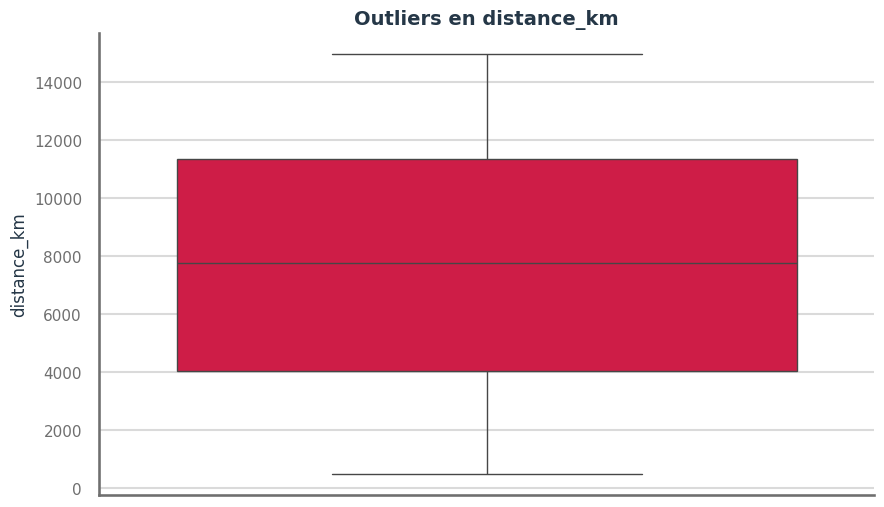

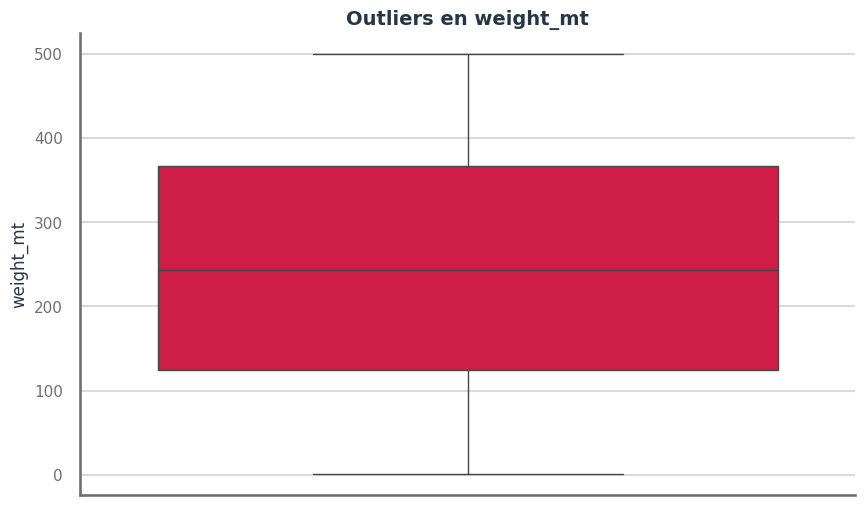

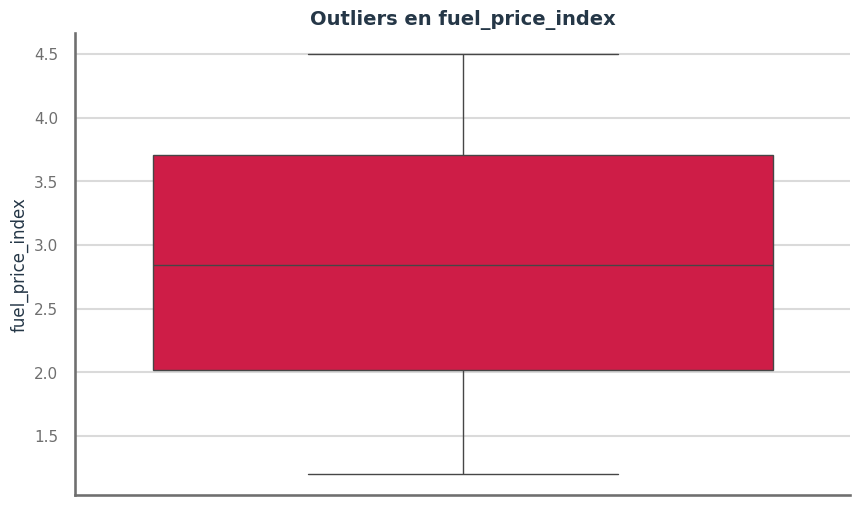

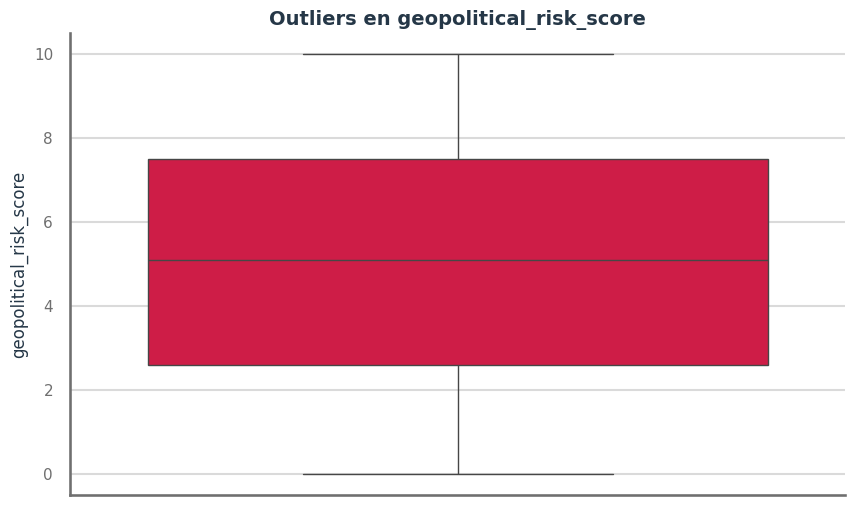

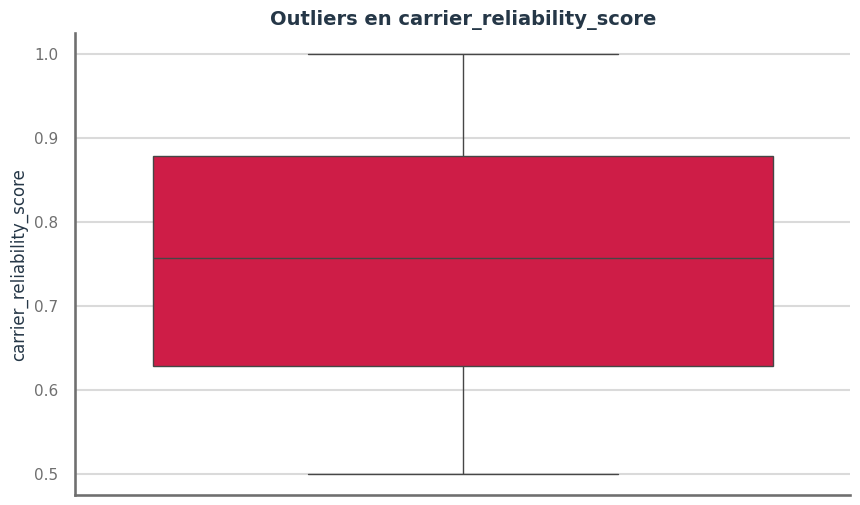

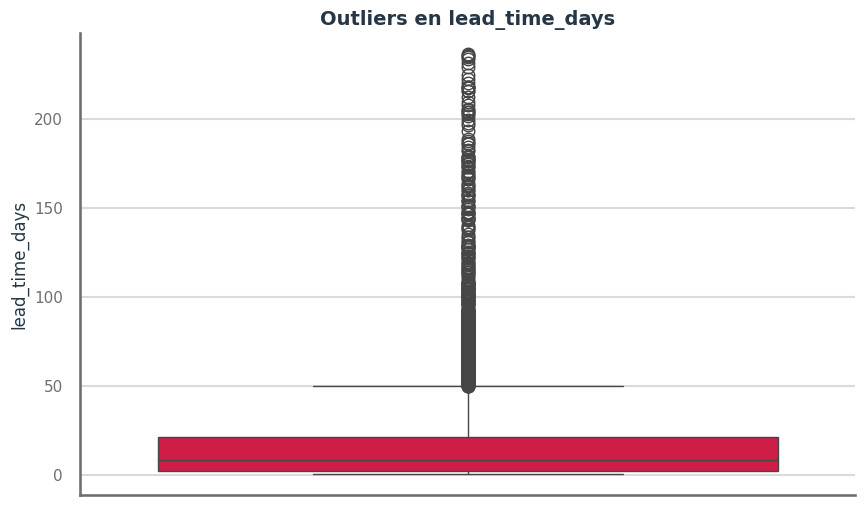

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

for col in numerical_cols:
    plt.figure()
    sns.boxplot(y=df[col])
    plt.title(f"Outliers en {col}")
    plt.show()

In [22]:
df_outliers = df[df["lead_time_days"] > 50]

In [23]:
df_outliers.groupby("transport_mode",observed=True).size()

transport_mode
rail    124
road    102
sea     291
dtype: int64

**Revisión 11/10/2026:** la afirmación previa sobre modos de transporte fue retirada. La tasa de disrupción es prácticamente igual en los cuatro modos (ver celda de tasas por modo). No hay evidencia de que un modo sea más confiable que otro en este dataset.

6. Validación de consistencia del dataset

3.1 ¿Los datos tienen sentido lógico entre sí?

In [24]:
summary = pd.DataFrame({
    "columna": df.columns,
    "nulos": df.isnull().sum(),
    "tipo": df.dtypes,
    "valores_unicos": df.nunique()
})

summary

,columna,nulos,tipo,valores_unicos
shipment_id,shipment_id,0,str,5000
date,date,0,datetime64[us],731
origin_port,origin_port,0,category,8
destination_port,destination_port,0,category,9
transport_mode,transport_mode,0,category,4
product_category,product_category,0,category,5
distance_km,distance_km,0,float64,4998
weight_mt,weight_mt,0,float64,4785
fuel_price_index,fuel_price_index,0,float64,331
geopolitical_risk_score,geopolitical_risk_score,0,float64,101


Se realizó una validación de consistencia del dataset, verificando valores nulos, rangos lógicos, duplicados y coherencia entre variables. No se identificaron inconsistencias críticas, por lo que los datos se consideran aptos para el análisis exploratorio

## 4 Análisis Exploratorio de Datos (EDA)

<p style="font-size:18px;">
Con el dataset previamente limpio y validado, el análisis se enfoca en identificar riesgos operativos, evaluar su impacto y generar insights para la toma de decisiones estratégicas en la cadena de suministro.
</p>

### 4.1 EDA DESCRIPTIVO. Identificación de riesgos
#### ¿Dónde está el problema?


Separación automática de variables numéricas y categóricas en función de su tipo de dato, con el objetivo de aplicar técnicas de análisis específicas a cada tipo de variable.Se realiza esta transformación para evitar errores y asegurar que variables categóricas puedan ser utilizadas en cálculos y modelos, ya que muchos métodos analíticos requieren variables numéricas

In [25]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

/tmp/ipykernel_110/3894701945.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object', 'category']).columns


#### Cuantificación de la variable clima. Codificación ordinal

#### Cuantificación de la variable clima. Codificación ordinal

**Revisión 11/10/2026.** El orden se ajustó a las tasas observadas de disrupción por condición meteorológica, no a una escala asumida:
clear (37%) < rain (42%) < fog (48%) < storm (80%) < hurricane (100%).

La diferencia entre fog y rain es estadísticamente significativa (z = 2,75; p ≈ 0,006), por lo que el orden fog > rain se toma de los datos.

Advertencia de circularidad: el orden se deriva del mismo resultado (`disruption_occurred`) que luego se busca explicar. Esto infla la asociación entre el clima y el impacto. Para una validación independiente se necesitan datos fuera de muestra.

Fundamento de referencia: OMM define la niebla como visibilidad horizontal < 1 km; la escala Saffir-Simpson (NHC) aplica solo a huracanes y mide viento sostenido. No existe escala oficial que ordene lluvia y tormenta por impacto logístico.


In [26]:
weather_map = {
    'clear':     0,   # tasa observada 37%
    'rain':      1,   # tasa observada 42%
    'fog':       2,   # tasa observada 48% (significativamente mayor que rain, p≈0,006)
    'storm':     3,   # tasa observada 80%
    'hurricane': 4    # tasa observada 100%
}

df['weather_severity'] = df['weather_condition'].str.lower().map(weather_map)

nulos_clima = df['weather_severity'].isna().sum()
assert nulos_clima == 0, f"ERROR: {nulos_clima} valores de clima sin mapear → revisar weather_map"
print("✓ Todos los valores de weather_condition mapeados correctamente.")
print(df.groupby('weather_condition', observed=True)['disruption_occurred'].mean().sort_values().round(3))


✓ Todos los valores de weather_condition mapeados correctamente.
weather_condition
clear        0.370
rain         0.420
fog          0.481
storm        0.795
hurricane    1.000
Name: disruption_occurred, dtype: float64


La cuantificación del clima se basa en una codificación ordinal, donde se asignan valores numéricos según el nivel de severidad, permitiendo incorporar esta variable en el modelo de forma coherente con su impacto en el riesgo.

Normalización de Variables

Normalización de variables (llevana una escala comparable (0–1)) y construcción del índice de impacto (Risk Scoring Model),basado en un modelo de scoring (ISO 31000, OECD).Fórmula estándar min-max: (x - min) / (max - min)
Referencia: OECD (2008). Handbook on Constructing Composite Indicators, §3.
Esta normalización garantiza que todas las variables estén en [0, 1],lo cual es requisito para sumarlas con pesos de forma coherente.

In [27]:
def minmax(series):
    """Normalización min-max estándar → escala [0, 1]."""
    return (series - series.min()) / (series.max() - series.min())

df['lead_time_norm'] = minmax(df['lead_time_days'])
df['geo_norm']       = minmax(df['geopolitical_risk_score'])
df['carrier_norm']   = 1 - minmax(df['carrier_reliability_score'])  # invertido: mayor confiabilidad = menor riesgo
df['weather_norm']   = df['weather_severity'] / df['weather_severity'].max()

print("Rangos tras normalización (deben ser [0.0 – 1.0]):")
for col in ['lead_time_norm','geo_norm','carrier_norm','weather_norm']:
    print(f"  {col}: [{df[col].min():.3f}, {df[col].max():.3f}]")


Rangos tras normalización (deben ser [0.0 – 1.0]):
  lead_time_norm: [0.000, 1.000]
  geo_norm: [0.000, 1.000]
  carrier_norm: [0.000, 1.000]
  weather_norm: [0.000, 1.000]


Es un modelo de scoring estándar en gestión de riesgos (ISO 31000) y en índices compuestos (OECD, 2008).

df['carrier_norm'] = 1 - df['carrier_reliability_score']  # ya invertido

Se realizó para asegurar la coherencia del modelo, ya que inicialmente la variable de confiabilidad tenía una relación inversa con el riesgo. Al invertirla, todas las variables contribuyen en la misma dirección al impacto.

In [28]:
df['impact'] = (
    df['lead_time_norm'] * 0.4 +
    df['geo_norm'] * 0.3 +
    df['carrier_norm'] * 0.2 +
    df['weather_norm'] * 0.1
)

Los pesos (0.4 lead_time / 0.3 geo / 0.2 carrier / 0.1 weather) se basan en conocimiento del dominio logístico, consistente con la metodología de indicadores compuestos de la OECD (2008), donde no existe una única asignación óptima y los pesos deben reflejar la relevancia operativa de cada factor.

Los pesos no se asignan únicamente por correlación, sino por impacto operativo directo:
- El lead_time afecta directamente los SLA y costos de operación → peso máximo (0.4).
- El riesgo geopolítico determina la viabilidad estratégica de la ruta → peso alto (0.3).
- El clima tiene alto impacto estadístico pero bajo control operativo → peso conservador (0.1).

Este equilibrio entre evidencia empírica y juicio experto es estándar en construcción de índices compuestos (OECD, 2008, §5.3). Los pesos pueden validarse o ajustarse mediante análisis de sensibilidad.


**Revisión 11/10/2026: sensibilidad de pesos.** Se mantienen los pesos base 0,4/0,3/0,2/0,1 por decisión del autor. Este análisis muestra si el ranking de rutas depende de esa elección.

In [29]:
# ── Análisis de sensibilidad de pesos (OECD 2008, paso 7) ──────────────────
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

df['route'] = df['origin_port'].astype(str) + " - " + df['destination_port'].astype(str)

escenarios = {
    'base 0.4/0.3/0.2/0.1':          (0.4, 0.3, 0.2, 0.1),
    'igual 0.25 c/u':                (0.25, 0.25, 0.25, 0.25),
    'lead time dominante 0.6/0.2/0.1/0.1': (0.6, 0.2, 0.1, 0.1),
    'geopolítico dominante 0.2/0.5/0.2/0.1': (0.2, 0.5, 0.2, 0.1),
}

ranks = {}
for nombre, (a, b, c, d) in escenarios.items():
    imp = a*df['lead_time_norm'] + b*df['geo_norm'] + c*df['carrier_norm'] + d*df['weather_norm']
    ranks[nombre] = imp.groupby(df['route']).mean().rank(ascending=False)
ranks = pd.DataFrame(ranks)

base = 'base 0.4/0.3/0.2/0.1'
resumen = []
for nombre in escenarios:
    top10_base = set(ranks[base].nsmallest(10).index)
    top10_esc  = set(ranks[nombre].nsmallest(10).index)
    resumen.append({
        'escenario': nombre,
        'spearman_vs_base': round(spearmanr(ranks[base], ranks[nombre]).correlation, 3),
        'rutas_top10_coinciden_con_base': len(top10_base & top10_esc),
    })
print(pd.DataFrame(resumen).to_string(index=False))


                            escenario  spearman_vs_base  rutas_top10_coinciden_con_base
                 base 0.4/0.3/0.2/0.1             1.000                              10
                       igual 0.25 c/u             0.933                               8
  lead time dominante 0.6/0.2/0.1/0.1             0.966                               9
geopolítico dominante 0.2/0.5/0.2/0.1             0.932                               7


#### ¿Qué variables explican el fenómeno?, exploración de relaciones.

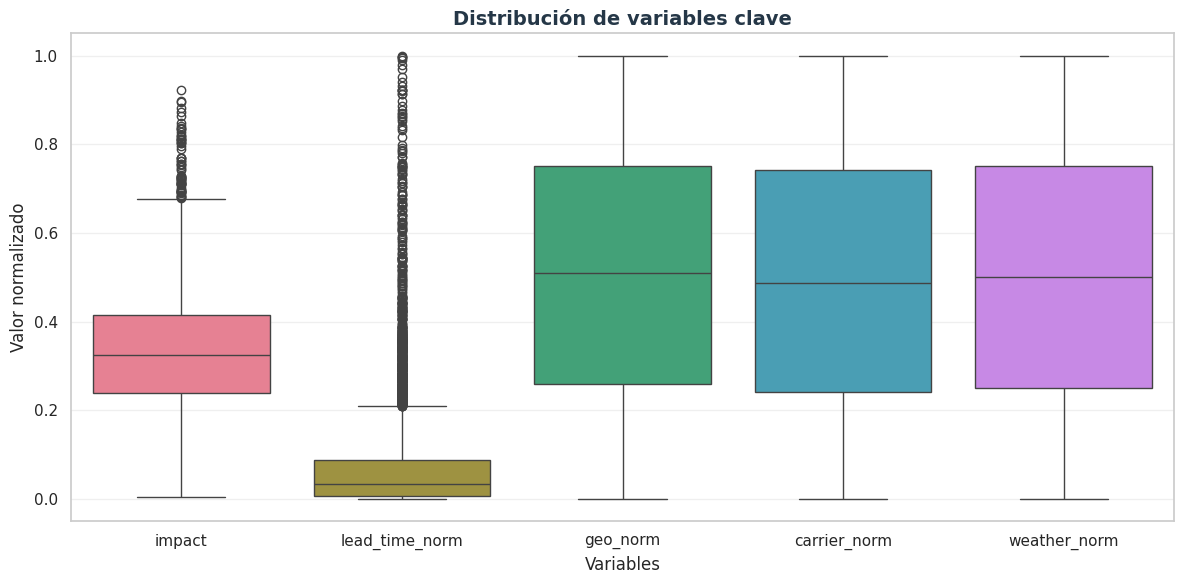

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

# Estilo general único
sns.set_theme(style="whitegrid", palette=["#c31566", "#6e6e6e"])

# Variables a comparar
cols = ['impact', 'lead_time_norm', 'geo_norm', 'carrier_norm', 'weather_norm']

# Boxplots de todas las variables
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df[cols],
   
)

plt.title("Distribución de variables clave", fontsize=14, fontweight="bold")
plt.xlabel("Variables")
plt.ylabel("Valor normalizado")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Aunque el lead time fue normalizado, mantuvo una distribución altamente sesgada con numerosos valores extremos. Por ello, se consideró la transformación logarítmica para estabilizar la dispersión y representar mejor su relación con el impacto.

CLima

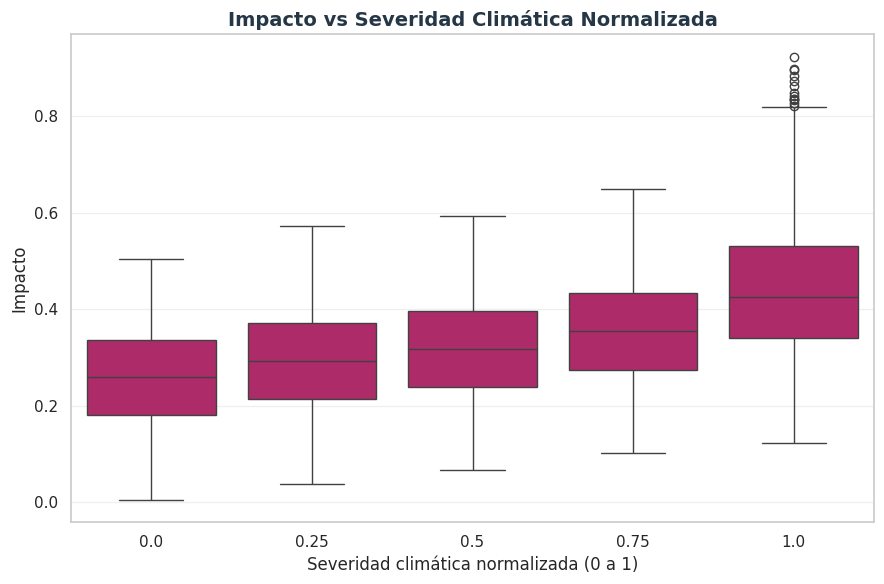

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt




# Boxplot: impacto vs severidad climática normalizada
plt.figure(figsize=(9,6))

sns.boxplot(
    data=df,
    x="weather_norm",
    y="impact",
  
)

plt.title("Impacto vs Severidad Climática Normalizada", fontsize=14, fontweight="bold")
plt.xlabel("Severidad climática normalizada (0 a 1)")
plt.ylabel("Impacto")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

El impacto aumenta progresivamente con la severidad climática. Además, en todos los niveles, los eventos con disrupción presentan impactos significativamente mayores.
La severidad climática actúa como amplificador del riesgo, incrementando tanto el impacto como la volatilidad operativa

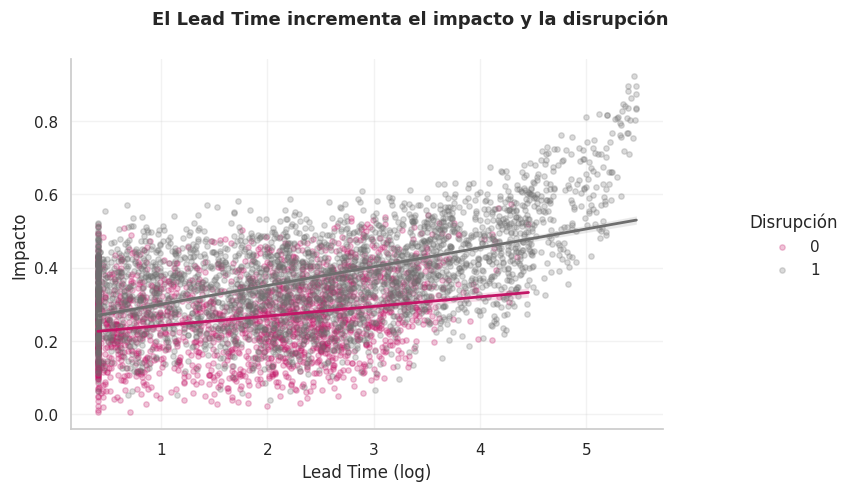

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Crear columna correcta si no existe
if 'lead_time_log' not in df.columns:
    if 'lead_time_days' in df.columns:
        df['lead_time_log'] = np.log1p(df['lead_time_days'])
    elif 'lead_time' in df.columns:
        df['lead_time_log'] = df['lead_time_days']


# Gráfico
g = sns.lmplot(
    data=df,
    x='lead_time_log',
    y='impact',
    hue='disruption_occurred',
    height=5,
    aspect=1.4,
    scatter_kws={'alpha':0.25, 's':15},
    line_kws={'linewidth':2}
)

g.set_axis_labels('Lead Time (log)', 'Impacto')

g.fig.suptitle(
    'El Lead Time incrementa el impacto y la disrupción',
    fontsize=13,
    fontweight='bold'
)

g.fig.subplots_adjust(top=0.88)

if g._legend:
    g._legend.set_title('Disrupción')

plt.show()

Se realizó un análisis exploratorio visual previo (pairplot) para identificar posibles relaciones entre variables, a partir del cual se seleccionaron las variables clave y se procedió con la matriz de correlación.

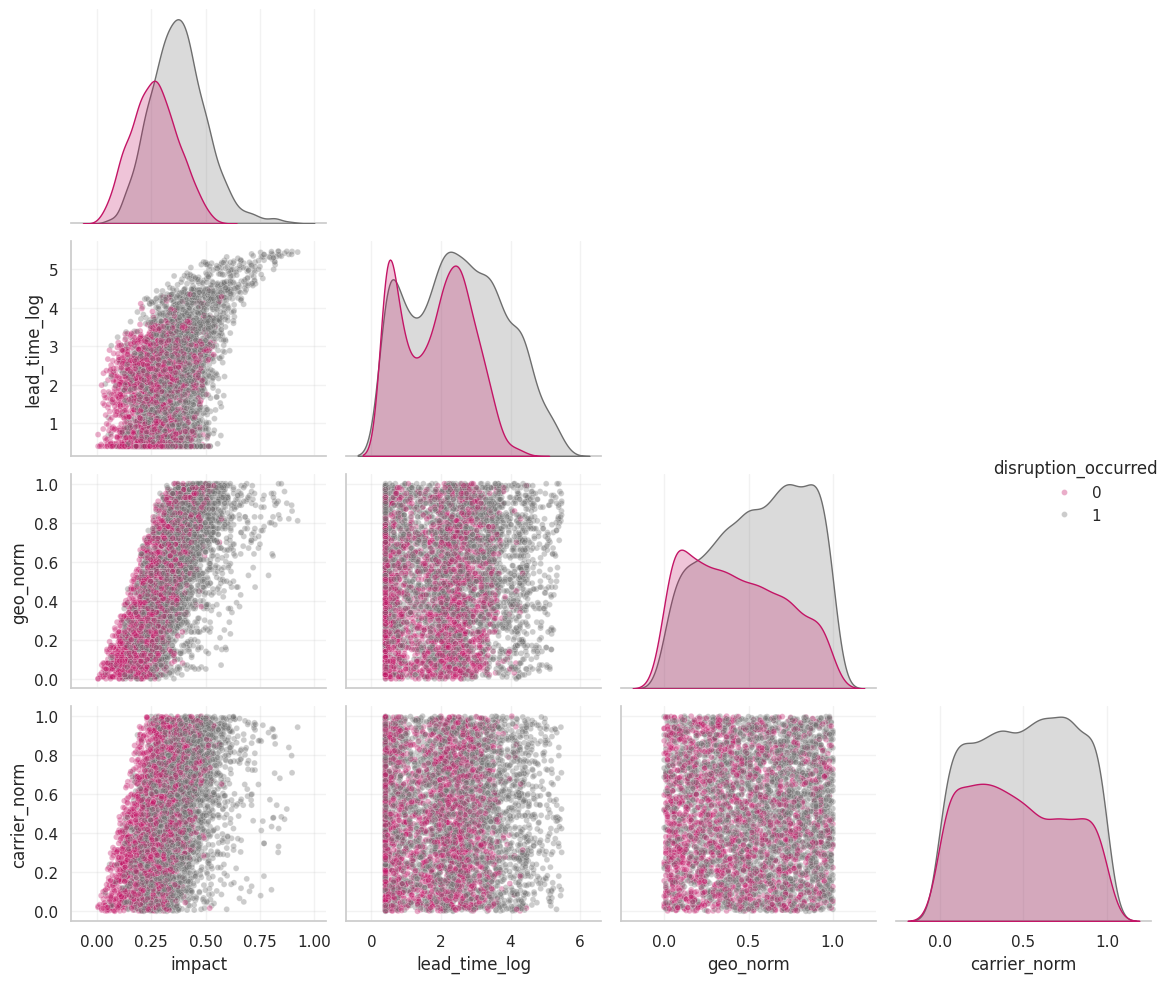

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = [
    'impact',
    'lead_time_log',
    'geo_norm',
    'carrier_norm'
]  # No incluyo clima porque distorsiona el gráfico; se evaluará por separado



sns.pairplot(
    df,
    vars=cols,
    hue='disruption_occurred',
    diag_kind='kde',
    corner=True,
   #plot_kws={'alpha': 0.8, 's': 45},
   # diag_kws={'fill': True, 'alpha': 0.6}
   plot_kws={'alpha':0.35, 's':18},
   diag_kws={'fill':True},
  
)

plt.tight_layout()
plt.show()

Se exploraron relaciones entre variables mediante visualización bivariada.
El lead time se analizó por separado debido a su distribución distinta, evitando distorsión en la interpretación

#### ¿Cuánto pesa cada variable?, cuantificación de drivers

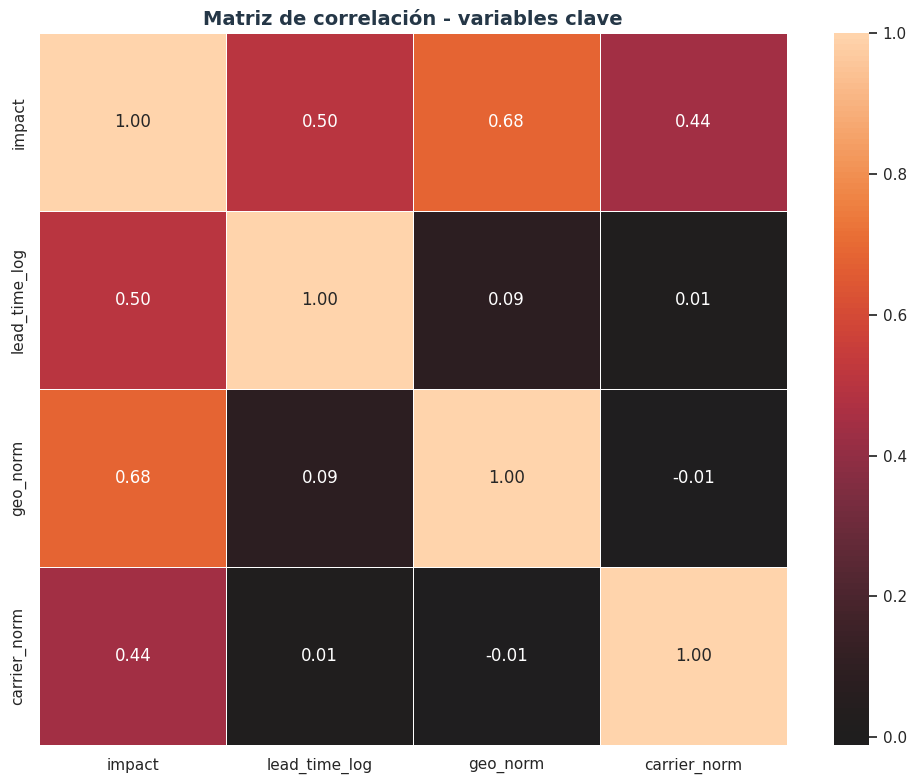

In [34]:


# Detectar columna correcta de lead time
if 'lead_time_log' in df.columns:
    lead_col = 'lead_time_log'
elif 'lead_time' in df.columns:
    lead_col = 'lead_time_days'
elif 'lead_time' in df.columns:
    df['lead_time_log'] = np.log1p(df['lead_time_days'])
    lead_col = 'lead_time_log'

# Variables clave
cols = ['impact', lead_col, 'geo_norm', 'carrier_norm']
corr_matrix = df[cols].corr()

# Heatmap
plt.figure(figsize=(10,8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",

    linewidths=0.5,
    center=0
)

plt.title("Matriz de correlación - variables clave", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

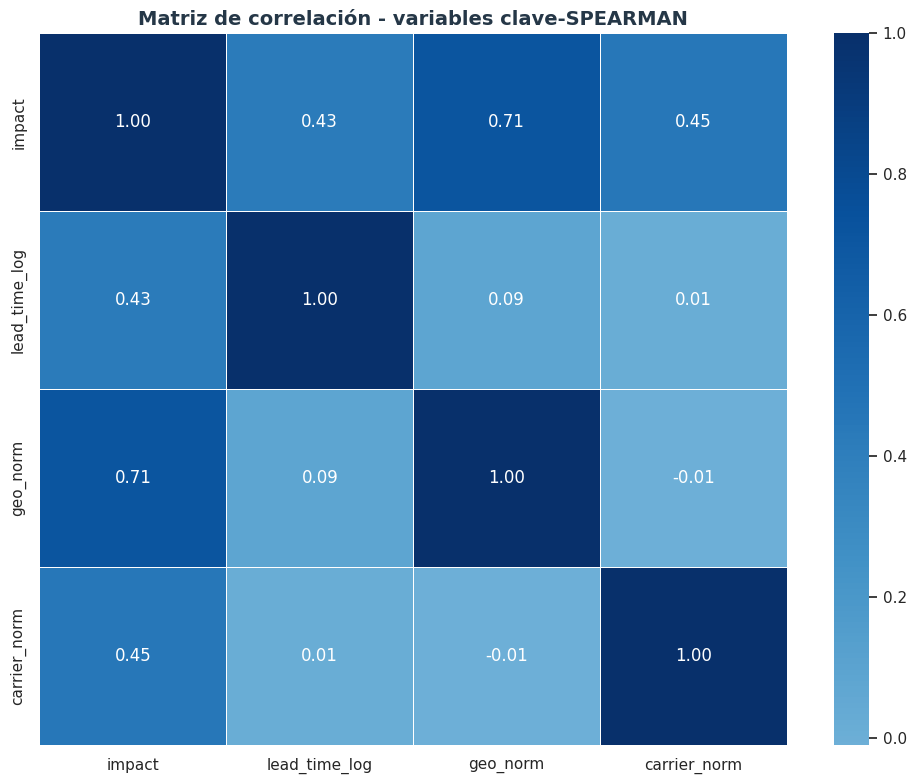

In [35]:

# Detectar columna correcta de lead time
if 'lead_time_log' in df.columns:
    lead_col = 'lead_time_log'
elif 'lead_time' in df.columns:
    lead_col = 'lead_time_days'
elif 'lead_time' in df.columns:
    df['lead_time_log'] = np.log1p(df['lead_time_days'])
    lead_col = 'lead_time_log'

# Variables clave
cols = ['impact', lead_col, 'geo_norm', 'carrier_norm']
corr_matrix = df[cols].corr(method='spearman')

# Heatmap
plt.figure(figsize=(10,8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
     cmap="Blues",
    linewidths=0.5,
    center=0
)

plt.title("Matriz de correlación - variables clave-SPEARMAN", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Spearman fue utilizado como contraste no paramétrico, confirmando resultados consistentes.

#### Segmentación del riesgo en base a la Variable disruption_type 
La clasificación de eventos disruptivos en categorías operacionalmente distintas responde a los principios de evaluación y tratamiento diferenciado del riesgo establecidos en la norma ISO 31000:2018, según la cual los riesgos deben analizarse considerando tanto su naturaleza como su magnitud para orientar decisiones de mitigación efectivas. En este estudio, cada registro fue segmentado en una de cuatro categorías — geopolitical, carrier_failure, operational_delay y no_disruption — mediante un algoritmo de clasificación basado en percentiles extremos (P90 y P10), donde cada ruta se asigna al tipo de disrupción en el que su desviación proporcional respecto al umbral crítico es máxima. Este enfoque, consistente con la literatura en gestión de riesgos en cadenas de suministro (Kulpa, 2024; Bednarski et al., 2024), evita la sobreclasificación jerárquica arbitraria y garantiza que cada evento quede representado por su señal de riesgo dominante. 

In [36]:
import pandas as pd
import numpy as np

# Umbrales basados en percentiles extremos (sin cambios respecto a la versión previa)
p90_geo   = df['geopolitical_risk_score'].quantile(0.90)
p10_rel   = df['carrier_reliability_score'].quantile(0.10)
p90_delay = df['lead_time_days'].quantile(0.90)

def classify_cause(row):
    scores = {}
    if row['geopolitical_risk_score'] > p90_geo:
        scores['geopolitical'] = (row['geopolitical_risk_score'] - p90_geo) / p90_geo
    if row['carrier_reliability_score'] < p10_rel:
        scores['carrier_failure'] = (p10_rel - row['carrier_reliability_score']) / p10_rel
    if row['lead_time_days'] > p90_delay:
        scores['operational_delay'] = (row['lead_time_days'] - p90_delay) / p90_delay
    return max(scores, key=scores.get) if scores else None

causa = df.apply(classify_cause, axis=1)

# Revisión 11/10/2026: la variable primaria es disruption_occurred.
# - Sin disrupción registrada  -> 'sin_disrupcion'
# - Disrupción registrada pero sin factor extremo identificable -> 'sin_causa_identificada'
# - Disrupción registrada con factor extremo -> causa dominante
df['disruption_type'] = np.where(
    df['disruption_occurred'] == 0,
    'sin_disrupcion',
    causa.fillna('sin_causa_identificada')
)

print("Distribución de tipos:")
print(df['disruption_type'].value_counts())
print()
print("Tabla cruzada disruption_occurred vs disruption_type:")
print(pd.crosstab(df['disruption_occurred'], df['disruption_type'], margins=True))
print()
print("Impacto promedio por tipo:")
print(df.groupby('disruption_type')['impact'].mean().sort_values(ascending=False).round(2))


Distribución de tipos:
disruption_type
sin_causa_identificada    2038
sin_disrupcion            1937
operational_delay          483
geopolitical               293
carrier_failure            249
Name: count, dtype: int64

Tabla cruzada disruption_occurred vs disruption_type:
disruption_type      carrier_failure  geopolitical  operational_delay  \
disruption_occurred                                                     
0                                  0             0                  0   
1                                249           293                483   
All                              249           293                483   

disruption_type      sin_causa_identificada  sin_disrupcion   All  
disruption_occurred                                                
0                                         0            1937  1937  
1                                      2038               0  3063  
All                                    2038            1937  5000  

Impacto promedio p

In [37]:
df.groupby('disruption_type')['impact'].mean().sort_values(ascending=False).round(2)

disruption_type
operational_delay         0.53
geopolitical              0.45
carrier_failure           0.42
sin_causa_identificada    0.32
sin_disrupcion            0.26
Name: impact, dtype: float64

**Revisión 11/10/2026:** las cifras de impacto promedio por tipo se recalcularon con la nueva clasificación (celda 70). La comparación entre tipos debe leerse junto con la tabla cruzada, ya que el índice de impacto usa las mismas variables que definen los tipos (ver celda 75).

#### ¿Cómo se traduce eso en negocio?, impacto en negocio

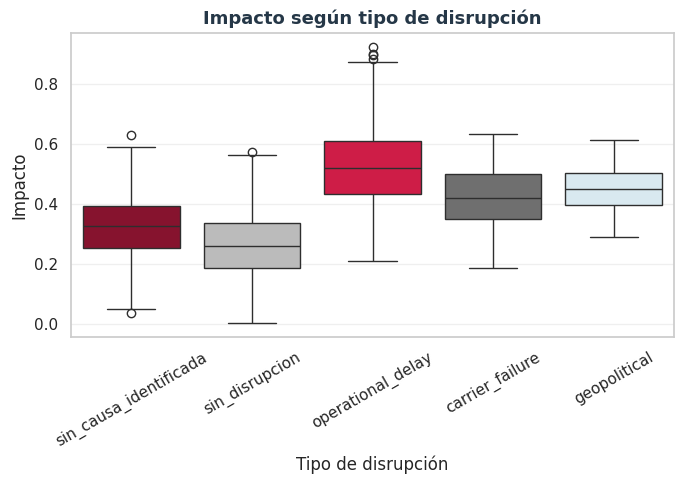

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

sns.boxplot(
    data=df,
    x="disruption_type",
    y="impact",
    hue="disruption_type",   # evita warning
    dodge=False,
    legend=False,
    palette={"operational_delay":"#EB0037","geopolitical":"#D5EAF4","carrier_failure":"#6F6F6F","sin_causa_identificada":"#990024","sin_disrupcion":"#BBBBBB"}
)

plt.title("Impacto según tipo de disrupción", fontsize=13, fontweight="bold")
plt.xlabel("Tipo de disrupción")
plt.ylabel("Impacto")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Revisión 11/10/2026: circularidad.** `disruption_type` se define con geopolítico, carrier y lead time, y el índice de impacto usa esas mismas variables. Por eso la separación de grupos en el boxplot no es evidencia independiente de validez. Se mantiene solo como descripción.

## 4.2 ¿En cuáles rutas ocurren las mayores disrupciones?

In [39]:
# Revisión 11/10/2026: ranking de rutas con intervalos de confianza al 95%
df["route"] = df["origin_port"].astype(str) + " - " + df["destination_port"].astype(str)

tasa_global = df["disruption_occurred"].mean()
route_stats = df.groupby("route")["disruption_occurred"].agg(tasa="mean", n="size")
se = np.sqrt(route_stats["tasa"] * (1 - route_stats["tasa"]) / route_stats["n"])
route_stats["ic95_inf"] = route_stats["tasa"] - 1.96 * se
route_stats["ic95_sup"] = route_stats["tasa"] + 1.96 * se
route_stats["supera_media_global"] = route_stats["ic95_inf"] > tasa_global
route_stats = route_stats.sort_values("tasa", ascending=False).round(3)

print(f"Tasa global de disrupción: {tasa_global:.3f}")
print(f"Rutas analizadas: {len(route_stats)}  |  con IC95 inferior > media global: {route_stats['supera_media_global'].sum()}")
route_stats.head(10)

rutas_top = route_stats.head(10).index
CAUSAS = ['operational_delay', 'geopolitical', 'carrier_failure']
df_top = df[df['route'].isin(rutas_top) & df['disruption_type'].isin(CAUSAS)]


Tasa global de disrupción: 0.613
Rutas analizadas: 64  |  con IC95 inferior > media global: 2


In [40]:
tabla = (
    df_top.groupby(["route", "disruption_type"])
    .size()
    .reset_index(name="conteo")
)

tabla["proporcion"] = (
    tabla["conteo"] /
    tabla.groupby("route")["conteo"].transform("sum")
)

tabla_pivot = (
    tabla.pivot(index="route", columns="disruption_type", values="proporcion")
    .fillna(0)
)
tabla_pivot.round(2)

disruption_type,carrier_failure,geopolitical,operational_delay
route,,,
busan - marseille,0.06,0.19,0.75
busan - shanghai,0.25,0.25,0.50
hamburg - los angeles,0.18,0.36,0.45
hamburg - rotterdam,0.31,0.12,0.56
los angeles - singapore,0.22,0.33,0.44
rotterdam - busan,0.22,0.26,0.52
rotterdam - marseille,0.00,0.25,0.75
shanghai - marseille,0.11,0.21,0.68
shanghai - singapore,0.29,0.19,0.52


In [41]:
# ── Pruebas de independencia (chi-cuadrado) ─────────────────────────────
from scipy.stats import chi2_contingency
import pandas as pd

for col in ['weather_condition', 'transport_mode', 'origin_port', 'destination_port']:
    t = pd.crosstab(df[col], df['disruption_occurred'])
    chi2, p, _, _ = chi2_contingency(t)
    print(f"{col:20s}  chi2 = {chi2:9.2f}   p = {p:.4f}")


weather_condition     chi2 =   1243.44   p = 0.0000
transport_mode        chi2 =      0.18   p = 0.9804
origin_port           chi2 =      1.86   p = 0.9671
destination_port      chi2 =      3.17   p = 0.9231


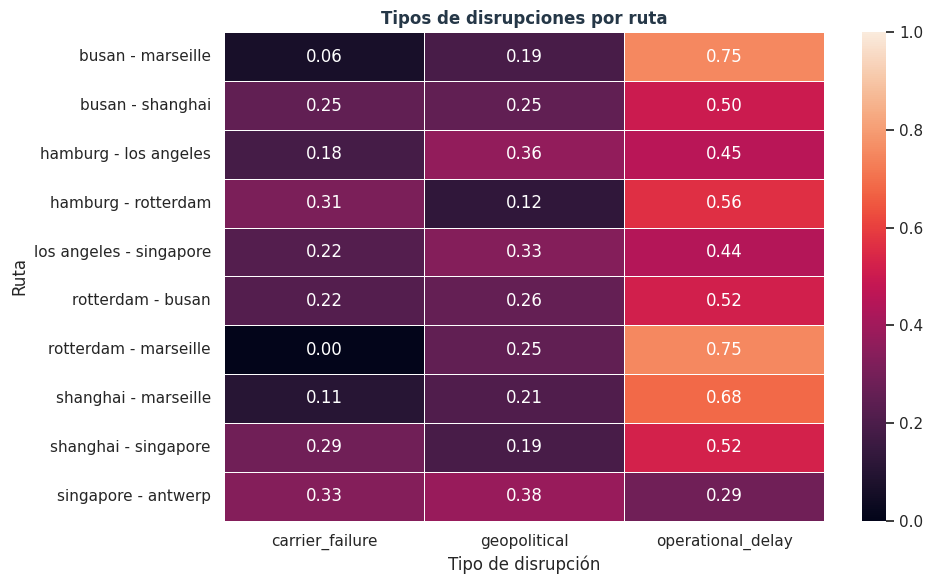

In [42]:
plt.figure(figsize=(10,6))

sns.heatmap(
    tabla_pivot,
    annot=True,        # muestra valores
    fmt=".2f",         # formato decimal
    
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title("Tipos de disrupciones por ruta")
plt.xlabel("Tipo de disrupción")
plt.ylabel("Ruta")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

**Revisión 11/10/2026:** la lista de rutas con mayor riesgo operativo se retiró. Sus intervalos de confianza se solapan y la prueba de independencia entre ruta y disrupción no es significativa (ver celda de pruebas). Las diferencias entre rutas no deben presentarse como riesgo diferencial.

**Revisión 11/10/2026:** el perfil por ruta se describe solo como exploratorio. Con los tamaños de muestra actuales, no se puede afirmar que el tipo de disrupción dominante sea distinto entre rutas.

##  P2 P3 ¿Qué tan impactante es el riesgo? y  ¿Dónde debo priorizar la inversión en mitigación? 
Para responder esta pregunta se construyó un **índice de impacto compuesto** bajo la metodología ISO 31000, combinando tres dimensiones operativas: días de retraso, distancia de la ruta y peso del envío. Este índice permite comparar rutas en una escala normalizada (0–1) independientemente de su volumen de tráfico.

In [43]:
# Revisión 11/10/2026: matriz ISO 31000 con criterios ABSOLUTOS provisionales (no terciles)
# Probabilidad alta: tasa de la ruta > tasa global de disrupción.
# Impacto alto: impacto medio de la ruta (índice de la celda 53) > impacto medio global.
# Los criterios deben ser confirmados por el autor antes de usarse en decisiones.
import numpy as np
import pandas as pd

tasa_global = df['disruption_occurred'].mean()
imp_global  = df['impact'].mean()

route_tbl = (
    df.groupby('route')
      .agg(probability=('disruption_occurred', 'mean'),
           impact_norm=('impact', 'mean'),
           n=('disruption_occurred', 'size'))
      .reset_index()
)
route_tbl['prob_alta']    = route_tbl['probability'] > tasa_global
route_tbl['impacto_alto'] = route_tbl['impact_norm'] > imp_global

def nivel_iso(r):
    if r['prob_alta'] and r['impacto_alto']:
        return 'Critical'
    if r['prob_alta'] or r['impacto_alto']:
        return 'High'
    return 'Low'

route_tbl['risk_level_iso'] = route_tbl.apply(nivel_iso, axis=1)

causas = df[df['disruption_type'].isin(['operational_delay', 'geopolitical', 'carrier_failure'])]
dom = causas.groupby('route')['disruption_type'].agg(lambda s: s.value_counts().idxmax())
route_tbl['disruption_type'] = route_tbl['route'].map(dom).fillna('sin_causa_identificada')

df_risk_matrix = route_tbl.copy()
print(f"Criterios: tasa global = {tasa_global:.3f}, impacto global = {imp_global:.3f}")
print(df_risk_matrix['risk_level_iso'].value_counts())
df_risk_matrix.sort_values('probability', ascending=False).round(3)


Criterios: tasa global = 0.613, impacto global = 0.333
risk_level_iso
Low         23
Critical    23
High        18
Name: count, dtype: int64


,route,probability,impact_norm,n,prob_alta,impacto_alto,risk_level_iso,disruption_type
45,rotterdam - marseille,0.750,0.344,68,True,True,Critical,operational_delay
39,los angeles - singapore,0.721,0.348,68,True,True,Critical,operational_delay
29,hamburg - rotterdam,0.708,0.344,72,True,True,Critical,operational_delay
41,rotterdam - busan,0.686,0.375,86,True,True,Critical,operational_delay
14,busan - shanghai,0.681,0.339,91,True,True,Critical,operational_delay
...,...,...,...,...,...,...,...,...
36,los angeles - marseille,0.542,0.292,72,False,False,Low,carrier_failure
37,los angeles - rotterdam,0.539,0.328,76,False,False,Low,geopolitical
35,los angeles - hamburg,0.525,0.301,59,False,False,Low,operational_delay
42,rotterdam - dubai,0.494,0.318,83,False,False,Low,operational_delay


No todas las rutas son igual de peligrosas, y eso es precisamente lo que este análisis nos permite ver.
Para medir el riesgo no basta con saber si hubo una disrupción, sino entender cuánto daño causó. Por eso combinamos dos cosas: qué tan seguido ocurren problemas en una ruta, y qué tan grave es cuando ocurren, tomando en cuenta el tiempo de retraso, la distancia y el volumen del envío. Un retraso de tres días en una ruta corta no es lo mismo que ese mismo retraso en un envío intercontinental de gran tonelaje.
El resultado es claro: el riesgo está concentrado en pocas rutas. Hay rutas que acumulan alta frecuencia de problemas y alto impacto cuando fallan, esas son las críticas y las que necesitan atención inmediata. Otras tienen riesgo elevado pero más manejable, y el resto puede simplemente monitorearse.
Otro hallazgo importante es que el tipo de problema importa. Las disrupciones de origen geopolítico, como cierres de fronteras o conflictos regionales, son las que generan mayor daño operativo. No son las más frecuentes, pero cuando ocurren, el impacto es significativamente mayor que el de un retraso operativo o un fallo de transportista.
En definitiva, el riesgo en esta red logística no se distribuye de forma homogénea. Saber dónde se concentra y por qué permite tomar decisiones más inteligentes, en lugar de tratar todas las rutas por igual.
Las rutas con mayor riesgo están determinadas principalmente por la frecuencia de disrupciones, mientras que el impacto se mantiene en niveles moderados, lo que sugiere una estrategia enfocada en mitigación operativa más que en gestión de eventos extremos.

**3. Clasificación ISO 31000 (revisión 11/10/2026).** Niveles: Critical = probabilidad alta e impacto alto; High = una de las dos; Low = ninguna. Los criterios (media global) son provisionales y deben ser confirmados por el autor (ISO 31000 §6.4.4 exige criterios definidos antes de evaluar). El nivel Medium fue retirado porque no tenía regla de asignación consistente con los criterios.

## P5 ¿ Qué acciones reducen el riesgo de forma inmediata?

In [44]:
import pandas as pd

# Revisión 11/10/2026: las acciones son HIPÓTESIS a validar con costo y evidencia; no son conclusiones del análisis.
map_riesgo = {
    'operational_delay':        'Operativo',
    'geopolitical':             'Geopolítico',
    'carrier_failure':          'Carrier',
    'sin_causa_identificada':   'Sin causa identificada',
    'sin_disrupcion':           'Sin disrupción',
}
df_risk_matrix['risk_type'] = df_risk_matrix['disruption_type'].map(map_riesgo)

def decision(row):
    nivel = row['risk_level_iso']
    tipo  = row['risk_type']
    if nivel == 'Critical':
        return 'Hipótesis: investigar causa y evaluar tratamiento (costo y efecto por validar)'
    if nivel == 'High':
        return 'Hipótesis: monitoreo reforzado y revisión de causa'
    return 'Monitoreo estándar'

df_risk_matrix['decision'] = df_risk_matrix.apply(decision, axis=1)
df_risk_matrix.sort_values('probability', ascending=False)[['route','risk_level_iso','probability','impact_norm','risk_type','decision']].round(3)


,route,risk_level_iso,probability,impact_norm,risk_type,decision
45,rotterdam - marseille,Critical,0.750,0.344,Operativo,Hipótesis: investigar causa y evaluar tratamie...
39,los angeles - singapore,Critical,0.721,0.348,Operativo,Hipótesis: investigar causa y evaluar tratamie...
29,hamburg - rotterdam,Critical,0.708,0.344,Operativo,Hipótesis: investigar causa y evaluar tratamie...
41,rotterdam - busan,Critical,0.686,0.375,Operativo,Hipótesis: investigar causa y evaluar tratamie...
14,busan - shanghai,Critical,0.681,0.339,Operativo,Hipótesis: investigar causa y evaluar tratamie...
...,...,...,...,...,...,...
36,los angeles - marseille,Low,0.542,0.292,Carrier,Monitoreo estándar
37,los angeles - rotterdam,Low,0.539,0.328,Geopolítico,Monitoreo estándar
35,los angeles - hamburg,Low,0.525,0.301,Operativo,Monitoreo estándar
42,rotterdam - dubai,Low,0.494,0.318,Operativo,Monitoreo estándar


**Revisión 11/10/2026:** la alineación entre nivel de riesgo y acción es una hipótesis de trabajo, no un resultado validado.

In [45]:
# Revisión 11/10/2026: matriz con cortes absolutos provisionales (medias globales)
import plotly.graph_objects as go

df_plot = df_risk_matrix.copy()
x_cut = tasa_global
y_cut = imp_global

COLOR = {'Critical': '#EB0037', 'High': '#FFA940', 'Low': '#52C41A'}

fig = go.Figure()
fig.add_shape(type='rect', x0=0, x1=1, y0=0, y1=1, fillcolor='rgba(0,0,0,0)', line_width=0)
fig.add_vline(x=x_cut, line_dash='dash', line_color='gray')
fig.add_hline(y=y_cut, line_dash='dash', line_color='gray')

for nivel, sub in df_plot.groupby('risk_level_iso'):
    fig.add_trace(go.Scatter(
        x=sub['probability'], y=sub['impact_norm'],
        mode='markers+text', text=sub['route'], textposition='top center',
        marker=dict(size=12, color=COLOR.get(nivel, 'gray')),
        name=nivel,
        hovertemplate='<b>%{text}</b><br>Probabilidad: %{x:.3f}<br>Impacto: %{y:.4f}<extra></extra>'
    ))

fig.update_layout(
    title='Matriz de riesgo ISO 31000 (criterios provisionales: medias globales)',
    xaxis_title='Probabilidad de disrupción (tasa por ruta)',
    yaxis_title='Impacto medio (índice, celda 53)',
    height=600, template='plotly_white'
)
fig.show()


Se utilizó impacto relativo porque las rutas tienen escalas muy diferentes. La normalización permite compararlas de forma homogénea y evitar sesgos por distancia o volumen.

El uso de impacto relativo permite una evaluación comparativa robusta, alineada con enfoques de priorización en gestión de riesgos bajo ISO 31000.

**IMPORTANTE**

Impacto absoluto → “cuánto duele en números reales”

Impacto relativo → “qué tan crítico es frente a otros”

## Conclusión — Visualización Matriz de Riesgo ISO (revisión 11/10/2026)

**Probabilidad.** La tasa global de disrupción es 61,3%. Las 10 rutas con mayor tasa van de 66% a 75%, pero sus intervalos de confianza se solapan con la media global.

**Solo 2 de 64 rutas** tienen un intervalo de confianza inferior por encima de la media global. **60 de 64** no se distinguen de ella. Las 10 rutas del ranking deben leerse como exploratorias, no como priorización.

**Clima.** Es la única variable con relación fuerte y significativa con la disrupción (chi-cuadrado p < 0,0001). Las rutas, el origen, el destino y el modo de transporte no tienen relación estadística.

**Criterios.** Los cortes de la matriz (medias globales) son provisionales. Hasta que el autor los confirme, los niveles Critical, High y Low no deben usarse para decidir inversiones.


# Monitoreo
El dashboard de visualización fue desarrollado con asistencia de IA (Claude, Anthropic). El diseño, los requisitos técnicos y las especificaciones fueron definidos por el autor, incluyendo el tipo de gráfico, las variables a representar, la paleta de colores, los KPIs y la estructura del mapa. La IA actuó como herramienta de implementación del código a partir de dichas instrucciones.

## Prompt(Instrucciones):

"Con los resultados de mi análisis de riesgo logístico, quiero un mapa mundial interactivo sobre fondo oscuro que conecte los puertos mediante rutas coloreadas en rojo, naranja y verde según su nivel de riesgo, con efecto de brillo en las líneas y tooltips al pasar el cursor. Que tenga indicadores clave en la parte superior como número de rutas por nivel de riesgo, probabilidad promedio y total de rutas. Debajo del mapa, una tabla estilo dashboard con todas las rutas, su nivel de riesgo, una barra visual de probabilidad, el tipo de disrupción y la decisión recomendada."

In [46]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np
import pandas as pd
from IPython.display import display, HTML

# Revisión 11/10/2026: el mapa y la tabla muestran solo las 10 rutas del ranking por tasa de disrupción
df_risk_matrix = df_risk_matrix[df_risk_matrix['route'].isin(rutas_top)].copy()

# ── Paleta de colores ─────────────────────────────────────────────────────────
color_map  = {'Critical': '#EB0037', 'High': '#ff4d4f', 'Medium': '#ffa940', 'Low': '#52c41a'}
width_map  = {'Critical': 5.5, 'High': 4.5, 'Medium': 3, 'Low': 2}
glow_map   = {'Critical': 'rgba(235,0,55,0.3)', 'High': 'rgba(255,77,79,0.3)', 'Medium': 'rgba(255,169,64,0.3)', 'Low': 'rgba(82,196,26,0.3)'}

# ── Coordenadas ───────────────────────────────────────────────────────────────
coords = {
    'rotterdam':   (4.4777,   51.9244),
    'busan':       (129.0756, 35.1796),
    'marseille':   (5.3698,   43.2965),
    'hamburg':     (10.0153,  53.5753),
    'shanghai':    (121.4737, 31.2304),
    'los angeles': (-118.4081,33.9425),
    'singapore':   (103.8198,  1.3521),
    'antwerp':     (4.4025,   51.2194),
}
hubs = ['rotterdam', 'shanghai', 'singapore']

# ── Funciones ─────────────────────────────────────────────────────────────────
def curva_geo(lon1, lat1, lon2, lat2, n=60):
    lons = np.linspace(lon1, lon2, n)
    lats = np.linspace(lat1, lat2, n)
    curva = np.sin(np.linspace(0, np.pi, n)) * 4
    lats = lats + curva
    return lons, lats

def distancia_km(lon1, lat1, lon2, lat2):
    R = 6371
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1; dlat = lat2 - lat1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

# ── FIGURA ────────────────────────────────────────────────────────────────────
fig = go.Figure()

# ── KPI Cards (anotaciones superiores) ───────────────────────────────────────
total       = len(df_risk_matrix)
high_count  = len(df_risk_matrix[df_risk_matrix['risk_level_iso'] == 'High'])
med_count   = len(df_risk_matrix[df_risk_matrix['risk_level_iso'] == 'Medium'])
low_count   = len(df_risk_matrix[df_risk_matrix['risk_level_iso'] == 'Low'])
avg_prob    = df_risk_matrix['probability'].mean()

kpis = [
    (f"🔴  {high_count}", "ALTO RIESGO",    "#ff4d4f", 0.08),
    (f"🟠  {med_count}",  "RIESGO MEDIO",   "#ffa940", 0.27),
    (f"🟢  {low_count}",  "BAJO RIESGO",    "#52c41a", 0.46),
    (f"📊  {avg_prob:.0%}","PROB. PROMEDIO", "#60a5fa", 0.65),
    (f"🛳️  {total}",      "RUTAS TOTALES",  "#a78bfa", 0.84),
]

for valor, etiqueta, color, xpos in kpis:
    fig.add_annotation(
        x=xpos, y=1.08,  # ← corregido de 1.13
        xref='paper', yref='paper',
        text=f'<b style="font-size:22px;color:{color}">{valor}</b>'
             f'<br><span style="font-size:10px;color:#8899aa;letter-spacing:2px">{etiqueta}</span>',
        showarrow=False, align='center',
        bgcolor='rgba(255,255,255,0.04)',
        bordercolor=color, borderwidth=1, borderpad=8
    )

# ── Rutas con efecto glow (doble trazo: sombra + línea) ───────────────────────
for _, row in df_risk_matrix.iterrows():
    origen, destino = [p.strip() for p in row['route'].split(' - ')]
    if origen not in coords or destino not in coords:
        continue

    nivel = row['risk_level_iso']
    lon1, lat1 = coords[origen]
    lon2, lat2 = coords[destino]
    lons, lats = curva_geo(lon1, lat1, lon2, lat2)
    distancia  = distancia_km(lon1, lat1, lon2, lat2)

    # Sombra (glow)
    fig.add_trace(go.Scattergeo(
        lon=lons, lat=lats, mode='lines',
        line=dict(width=width_map[nivel] + 5, color=glow_map[nivel]),
        opacity=0.4, showlegend=False, hoverinfo='skip'
    ))

    # Línea principal
    tooltip = (
        f"<b>🛳 {origen.title()} → {destino.title()}</b><br>"
        f"━━━━━━━━━━━━━━━━━━━━<br>"
        f"⚠️ Riesgo ISO: <b style='color:{color_map[nivel]}'>{nivel}</b><br>"
        f"📏 Distancia: <b>{distancia:,.0f} km</b><br>"
        f"🎯 Probabilidad: <b>{row['probability']:.0%}</b><br>"
        f"🔧 Tipo: <b>{row['risk_type']}</b><br>"
        f"━━━━━━━━━━━━━━━━━━━━<br>"
        f"📋 <i>{row['decision']}</i>"
        "<extra></extra>"
    )
    fig.add_trace(go.Scattergeo(
        lon=lons, lat=lats, mode='lines',
        line=dict(width=width_map[nivel], color=color_map[nivel]),
        opacity=0.9, showlegend=False, hovertemplate=tooltip
    ))

# ── Leyenda manual ────────────────────────────────────────────────────────────
for nivel, label in [('High','⚠ Alto Riesgo'), ('Medium','⚡ Riesgo Medio'), ('Low','✔ Bajo Riesgo')]:
    fig.add_trace(go.Scattergeo(
        lon=[None], lat=[None], mode='lines',
        line=dict(width=3, color=color_map[nivel]),
        name=label
    ))

# ── Marcadores de ciudades ────────────────────────────────────────────────────
orden = {'Critical': 4, 'High': 3, 'Medium': 2, 'Low': 1}
city_risk = {}
for _, row in df_risk_matrix.iterrows():
    for p in row['route'].split(' - '):
        p = p.strip()
        if p not in city_risk or orden[row['risk_level_iso']] > orden.get(city_risk[p], 0):
            city_risk[p] = row['risk_level_iso']

lons_c, lats_c, textos, colores, sizes, symbols = [], [], [], [], [], []
for ciudad, (lon, lat) in coords.items():
    lons_c.append(lon); lats_c.append(lat)
    textos.append(ciudad.title())
    colores.append(color_map.get(city_risk.get(ciudad, 'Low')))
    is_hub = ciudad in hubs
    sizes.append(18 if is_hub else 11)
    symbols.append('star' if is_hub else 'circle')

fig.add_trace(go.Scattergeo(
    lon=lons_c, lat=lats_c,
    mode='markers+text',
    marker=dict(size=sizes, color=colores, symbol=symbols,
                line=dict(width=2, color='white')),
    text=textos,
    textposition='top center',
    textfont=dict(size=11, color='white', family='monospace'),
    showlegend=False,
    hovertemplate="<b>🏭 %{text}</b><extra></extra>"
))

# ── Layout ────────────────────────────────────────────────────────────────────
fig.update_layout(
    title=dict(
        text='<b>GLOBAL LOGISTICS NETWORK</b>  '
             '<span style="font-size:13px;color:#60a5fa">● LIVE MONITOR</span><br>'
             '<sup style="color:#8899aa;letter-spacing:3px">RISK CLASSIFICATION — ISO 31000</sup>',
        x=0.5, font=dict(size=22, color='white', family='monospace')
    ),
    paper_bgcolor='#060d1a',
    geo=dict(
        showland=True,       landcolor='#111827',
        showocean=True,      oceancolor='#060d1a',
        showcoastlines=True, coastlinecolor='#1e3a5f',
        showcountries=True,  countrycolor='#1a2742',
        showrivers=False,
        projection_type='natural earth',
        bgcolor='#060d1a',
        lataxis_range=[-60, 80],
    ),
    legend=dict(
        bgcolor='rgba(6,13,26,0.85)',
        font=dict(color='white', size=11, family='monospace'),
        bordercolor='#1e3a5f', borderwidth=1,
        x=0.01, y=0.06
    ),
    height=680,
    margin=dict(l=0, r=0, t=160, b=0)  # ← corregido de 130
)

fig.show()

# ══════════════════════════════════════════════════════════════════════════════
# ── TABLA HTML ESTILO DASHBOARD ───────────────────────────────────────────────
# ══════════════════════════════════════════════════════════════════════════════

badge = {
    'Critical': '<span style="background:#EB0037;color:white;padding:2px 10px;border-radius:12px;font-weight:bold;font-size:11px">CRITICAL</span>',
    'High':   '<span style="background:#ff4d4f;color:white;padding:2px 10px;border-radius:12px;font-weight:bold;font-size:11px">🔴 HIGH</span>',
    'Medium': '<span style="background:#ffa940;color:white;padding:2px 10px;border-radius:12px;font-weight:bold;font-size:11px">🟠 MEDIUM</span>',
    'Low':    '<span style="background:#52c41a;color:white;padding:2px 10px;border-radius:12px;font-weight:bold;font-size:11px">🟢 LOW</span>',
}

tipo_icon = {'Carrier': '🚢', 'Operativo': '⚙️', 'Geopolítico': '🌐'}

df_show = df_risk_matrix[['route','risk_level_iso','probability','risk_type','decision']].copy()
df_show = df_show.sort_values('risk_level_iso', key=lambda x: x.map({'Critical':0,'High':1,'Medium':2,'Low':3}))

filas_html = ""
for _, row in df_show.iterrows():
    nivel  = row['risk_level_iso']
    icono  = tipo_icon.get(row['risk_type'], '📌')
    prob   = row['probability']
    color_barra = color_map[nivel]

    barra = (
        f'<div style="display:flex;align-items:center;gap:8px">'
        f'<div style="background:#1e3a5f;border-radius:4px;width:100px;height:8px">'
        f'<div style="background:{color_barra};width:{prob*100:.0f}px;height:8px;border-radius:4px"></div>'
        f'</div>'
        f'<span style="color:{color_barra};font-weight:bold">{prob:.0%}</span>'
        f'</div>'
    )

    filas_html += f"""
    <tr style="border-bottom:1px solid #1e3a5f">
      <td style="padding:10px 14px;color:#e2e8f0;font-family:monospace">
        🛳 {row['route'].title()}
      </td>
      <td style="padding:10px 14px;text-align:center">{badge[nivel]}</td>
      <td style="padding:10px 14px">{barra}</td>
      <td style="padding:10px 14px;color:#94a3b8;text-align:center">{icono} {row['risk_type']}</td>
      <td style="padding:10px 14px;color:#cbd5e1;font-size:12px">{row['decision']}</td>
    </tr>"""

tabla_html = f"""
<div style="background:#060d1a;border:1px solid #1e3a5f;border-radius:12px;
            padding:0;overflow-x:auto;font-family:monospace;margin-top:16px">
  <div style="background:#0b1628;padding:14px 20px;border-bottom:1px solid #1e3a5f;
              display:flex;justify-content:space-between;align-items:center">
    <span style="color:white;font-size:15px;font-weight:bold;letter-spacing:2px">
      📋 TABLA DE DECISIONES — MONITOREO DE RUTAS
    </span>
    <span style="color:#60a5fa;font-size:11px">ISO 31000 · {len(df_show)} rutas analizadas</span>
  </div>
  <table style="width:100%;border-collapse:collapse">
    <thead>
      <tr style="background:#0b1628;color:#60a5fa;font-size:11px;letter-spacing:2px">
        <th style="padding:10px 14px;text-align:left">RUTA</th>
        <th style="padding:10px 14px;text-align:center">NIVEL ISO</th>
        <th style="padding:10px 14px;text-align:left">PROBABILIDAD</th>
        <th style="padding:10px 14px;text-align:center">TIPO</th>
        <th style="padding:10px 14px;text-align:left">DECISIÓN RECOMENDADA</th>
      </tr>
    </thead>
    <tbody>{filas_html}</tbody>
  </table>
</div>
"""

display(HTML(tabla_html))

RUTA,NIVEL ISO,PROBABILIDAD,TIPO,DECISIÓN RECOMENDADA
🛳 Busan - Marseille,CRITICAL,68%,⚙️ Operativo,Hipótesis: investigar causa y evaluar tratamiento (costo y efecto por validar)
🛳 Busan - Shanghai,CRITICAL,68%,⚙️ Operativo,Hipótesis: investigar causa y evaluar tratamiento (costo y efecto por validar)
🛳 Hamburg - Los Angeles,CRITICAL,67%,⚙️ Operativo,Hipótesis: investigar causa y evaluar tratamiento (costo y efecto por validar)
🛳 Hamburg - Rotterdam,CRITICAL,71%,⚙️ Operativo,Hipótesis: investigar causa y evaluar tratamiento (costo y efecto por validar)
🛳 Los Angeles - Singapore,CRITICAL,72%,⚙️ Operativo,Hipótesis: investigar causa y evaluar tratamiento (costo y efecto por validar)
🛳 Rotterdam - Busan,CRITICAL,69%,⚙️ Operativo,Hipótesis: investigar causa y evaluar tratamiento (costo y efecto por validar)
🛳 Rotterdam - Marseille,CRITICAL,75%,⚙️ Operativo,Hipótesis: investigar causa y evaluar tratamiento (costo y efecto por validar)
🛳 Shanghai - Marseille,CRITICAL,66%,⚙️ Operativo,Hipótesis: investigar causa y evaluar tratamiento (costo y efecto por validar)
🛳 Shanghai - Singapore,CRITICAL,68%,⚙️ Operativo,Hipótesis: investigar causa y evaluar tratamiento (costo y efecto por validar)
🛳 Singapore - Antwerp,CRITICAL,68%,🌐 Geopolítico,Hipótesis: investigar causa y evaluar tratamiento (costo y efecto por validar)


## De la matriz al mapa — rutas del ranking

El mapa y la tabla de abajo muestran las **10 rutas con mayor tasa de disrupción** (ver celda de ranking con intervalos de confianza). El color indica el nivel de la matriz ISO con los criterios provisionales.

Las acciones de la tabla son hipótesis a validar con costo y evidencia, no recomendaciones. Con los intervalos actuales, la mayoría de estas rutas no se distingue estadísticamente de la media global.


In [47]:
import subprocess
subprocess.run([
    'jupyter', 'nbconvert', '--to', 'html',
    'Proyecto_logistica_corregido.ipynb',
    '--output', 'dashboard_logistica.html'
])
print("✅ Archivo HTML generado")

[NbConvertApp] Converting notebook Proyecto_logistica_corregido.ipynb to html


/usr/local/share/jupyter/nbconvert/templates/base/display_priority.j2:32: UserWarning: Your element with mimetype(s) dict_keys(['application/vnd.plotly.v1+json']) is not able to be represented.
  {%- elif type == 'text/vnd.mermaid' -%}


[NbConvertApp] WARNING | Alternative text is missing on 14 image(s).
[NbConvertApp] Writing 2070477 bytes to dashboard_logistica.html


✅ Archivo HTML generado


## 8. Validación temporal (partición 2024 vs. 2025)

**Revisión 11/10/2026.** Como validación interna, se usa el propio dataset: 2024 se toma como periodo de referencia y 2025 como periodo de prueba. Los criterios no se reajustan con 2025. Se comprueba si el clima, las rutas y el modo de transporte se comportan igual en ambos años.

Límite: el dataset es sintético, por lo que esto valida consistencia interna, no validez externa. Un generador con patrones estables reproduce los mismos resultados en ambos años.

In [48]:
# Validación temporal: referencia 2024, prueba 2025 (criterios no reajustados)
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, spearmanr

df['year'] = pd.to_datetime(df['date']).dt.year if 'date' in df.columns else df.index.map(lambda _: np.nan)

print("Envíos por año:", df['year'].value_counts().sort_index().to_dict())
print("Tasa global por año:", df.groupby('year')['disruption_occurred'].mean().round(3).to_dict())
print()

print("Tasa por clima y año:")
print(df.pivot_table(index='weather_condition', columns='year', values='disruption_occurred', aggfunc='mean').round(3))
print()

for col in ['transport_mode', 'origin_port']:
    t = pd.crosstab(df[col], df['year'])
    chi2, p, _, _ = chi2_contingency(t)
    print(f"{col}: independencia de año, chi2={chi2:.2f}, p={p:.3f}")

g = df.groupby(['route', 'year'])['disruption_occurred'].mean().unstack('year').dropna()
rho = spearmanr(g[2024], g[2025]).correlation
print(f"\nRutas con datos en ambos años: {len(g)}")
print(f"Spearman de la tasa por ruta, 2024 vs 2025: {rho:.3f}")


Envíos por año: {2024: 2455, 2025: 2545}
Tasa global por año: {2024: 0.62, 2025: 0.606}

Tasa por clima y año:
year                2024   2025
weather_condition              
clear              0.382  0.359
fog                0.486  0.475
hurricane          1.000  1.000
rain               0.436  0.402
storm              0.795  0.795

transport_mode: independencia de año, chi2=0.73, p=0.867
origin_port: independencia de año, chi2=8.44, p=0.295

Rutas con datos en ambos años: 64
Spearman de la tasa por ruta, 2024 vs 2025: -0.122


## 8b. Exportación para Power BI

Esta celda escribe las tablas que alimentan el tablero de Power BI en la carpeta `powerbi/`. Usa las mismas variables del análisis, así que los números coinciden con el notebook.

In [49]:
# Exportación de tablas para Power BI (carpeta powerbi/)
import os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

os.makedirs('powerbi', exist_ok=True)

# Verificación de variables necesarias
for nombre in ['df', 'route_stats', 'df_risk_matrix', 'ranks', 'tasa_global']:
    assert nombre in globals(), f"Falta la variable {nombre}; ejecuta las celdas anteriores"

def ic95(p, n):
    se = np.sqrt(p * (1 - p) / n)
    return p - 1.96 * se, p + 1.96 * se

# 1. KPIs generales
imp_media = df['impact'].mean()
kpi = pd.DataFrame({
    'kpi': ['envios', 'tasa_global_disrupcion', 'rutas_analizadas',
            'rutas_ic_inf_sobre_media', 'rutas_ic_sup_bajo_media', 'rutas_no_distinguibles',
            'disrupciones_totales', 'disrupciones_con_causa_identificada'],
    'valor': [
        len(df),
        round(tasa_global, 4),
        df['route'].nunique(),
        int((route_stats['ic95_inf'] > tasa_global).sum()),
        int((route_stats['ic95_sup'] < tasa_global).sum()),
        int(((route_stats['ic95_inf'] <= tasa_global) & (route_stats['ic95_sup'] >= tasa_global)).sum()),
        int(df['disruption_occurred'].sum()),
        int(((df['disruption_occurred'] == 1) &
             df['disruption_type'].isin(['operational_delay', 'geopolitical', 'carrier_failure'])).sum()),
    ],
})
kpi.to_csv('powerbi/1_kpis.csv', index=False)

# 2. Clima con intervalos y tasas por año
clima = df.groupby('weather_condition').agg(envios=('disruption_occurred', 'size'),
                                            tasa=('disruption_occurred', 'mean')).reset_index()
lo, hi = ic95(clima['tasa'], clima['envios'])
clima['ic95_inf'], clima['ic95_sup'] = lo, hi
anual = df.pivot_table(index='weather_condition', columns='year',
                       values='disruption_occurred', aggfunc='mean').reset_index()
anual.columns = ['weather_condition', 'tasa_2024', 'tasa_2025']
clima = clima.merge(anual, on='weather_condition').round(4)
clima.to_csv('powerbi/2_clima.csv', index=False)

# 3. Rutas con intervalos de confianza
rutas = route_stats.reset_index().rename(columns={'index': 'route'})
if 'route' not in rutas.columns:
    rutas = rutas.rename(columns={rutas.columns[0]: 'route'})
rutas['ranking_top10'] = rutas['tasa'].rank(ascending=False, method='first') <= 10
rutas.round(4).to_csv('powerbi/3_rutas_ic.csv', index=False)

# 4. Matriz de riesgo (criterios provisionales)
matriz = df_risk_matrix.copy()
matriz = matriz.merge(rutas[['route', 'ic95_inf', 'ic95_sup', 'ranking_top10']], on='route', how='left')
matriz.round(4).to_csv('powerbi/4_matriz_riesgo.csv', index=False)

# 5. Sensibilidad de pesos (usa las puntuaciones calculadas en la celda de sensibilidad)
base = 'base 0.4/0.3/0.2/0.1'
sens = pd.DataFrame([{
    'escenario': n,
    'spearman_vs_base': round(spearmanr(ranks[base], ranks[n]).correlation, 3),
    'top10_coincide_con_base': len(set(ranks[base].nsmallest(10).index) & set(ranks[n].nsmallest(10).index)),
} for n in ranks.columns])
sens.to_csv('powerbi/5_sensibilidad_pesos.csv', index=False)

# 6. Validación temporal por año
temporal = df.groupby('year').agg(envios=('disruption_occurred', 'size'),
                                  tasa=('disruption_occurred', 'mean')).reset_index().round(4)
temporal.to_csv('powerbi/6_validacion_temporal.csv', index=False)

print('Archivos exportados en powerbi/:', sorted(os.listdir('powerbi')))


Archivos exportados en powerbi/: ['1_kpis.csv', '2_clima.csv', '3_rutas_ic.csv', '4_matriz_riesgo.csv', '5_sensibilidad_pesos.csv', '6_validacion_temporal.csv']


## Registro de revisión

**Fecha de la revisión: domingo 11 de octubre de 2026.**

Cambios aplicados sobre `Proyecto_logistica_definitivo.ipynb`:

- Ruta de lectura del CSV actualizada.
- Celda 36: afirmación sobre modo de transporte retirada (sin soporte estadístico).
- Celdas 46-47: orden del clima ajustado a tasas observadas (fog > rain, p≈0,006); advertencia de circularidad añadida.
- Celda 70: etiqueta "no_disruption" reemplazada por clasificación coherente con disruption_occurred (sin_disrupcion / sin_causa_identificada / causa).
- Celdas 72 y 75: interpretaciones previas reemplazadas; circularidad declarada.
- Nueva celda: análisis de sensibilidad de pesos (cuatro escenarios, Spearman y solapamiento top-10).
- Celda 77: ranking de rutas reemplazado por tabla con IC95; se indica cuántas rutas superan la media global.
- Matriz ISO: terciles reemplazados por criterios absolutos provisionales (media global); una sola definición de impacto (celda 53).
- Celda 87: acciones con porcentajes fijos retiradas; ahora son hipótesis a validar.
- Celda 89: gráfico con cortes absolutos; iconos retirados (ya no hay categorías de tres factores en el mapa).
- Nueva celda: pruebas chi-cuadrado de independencia (clima, modo, origen, destino).
- Celda de exportación HTML: nombre de archivo alineado con la copia corregida.
- Dashboard (mapa y tabla): nivel Critical añadido a colores, anchos, prioridad y tabla, porque la nueva matriz lo usa.

No modificados: pesos del índice (0,4/0,3/0,2/0,1), tratamiento de outliers, normalización min-max, textos del dashboard. La sección de app Streamlit fue eliminada; el dashboard se reemplaza por Power BI. El mapa ahora dibuja las 64 rutas, no solo las 10 del ranking anterior.

**Revisión posterior (11/10/2026):** el mapa y la tabla del dashboard muestran solo las 10 rutas del ranking. Se actualizaron la conclusión y el texto que acompaña la tabla, para reflejar los resultados actuales. Se eliminó la sección de app Streamlit.

**Revisión de fuente y limitaciones (11/10/2026):** se confirmó en la ficha de Kaggle que el dataset es sintético; se añadió la portada con fuente, período real y limitaciones; se corrigió el período en la sección de carga.

**Validación temporal (11/10/2026):** se añadió la sección 8 con partición 2024 (referencia) y 2025 (prueba). Clima estable; rutas sin persistencia (Spearman −0,12). Límite: dataset sintético, validación interna.

**Pendiente de decisión del autor:** los criterios de la matriz (media global) son provisionales. Solo 2 de 64 rutas tienen un intervalo de confianza inferior por encima de la media global, por lo que la clasificación Critical no es estadísticamente robusta.
